# 錯誤更正碼 1123

1116 講義介紹了 belief propagation（BP），  
也在 BEC 上用 density evolution 算出 $(3, 6)$ 的 threshold $0.4294$。  
今天補上三件事。  
第一，BP 的兩條規則為什麼成立。  
第二，在 BEC 以外的 channels 上怎麼估計 density evolution。  
第三，在 BEC 上怎麼讓 threshold 逼近 capacity。

食譜
- 平行的觀測，likelihood ratios 相乘；串聯的 bits，biases 相乘。
- BMS channel 是 BSCs 的混合。
- VN 的 Bhattacharyya parameter 相乘，CN 的 total variation 相乘。
- 另一種 node 用 BEC 與 BSC 估計，把 density evolution 夾住。
- Irregular degrees：stability condition 與 flatness condition。
- Spatial coupling：BP threshold 升到 potential threshold。

## Sum-Product Rule

### 一個 bit 的三種記法

傳送一個 bit $x$，收到 $y$。  
1116 講義用過三種方式記錄 $y$ 帶來的資訊：
$$\ell = \frac{\Pr(y \mid x = 0)}{\Pr(y \mid x = 1)},\qquad L = \ln\ell,\qquad
\beta = \mathbb E\bigl[(-1)^x \mid y\bigr],$$
分別稱為 likelihood ratio、LLR、bias。

$x$ 均勻分布時，由 Bayes 公式，posterior 的比值就是 $\ell$：
$$\frac{\Pr(x = 0 \mid y)}{\Pr(x = 1 \mid y)}
= \frac{\Pr(y \mid x = 0)}{\Pr(y \mid x = 1)} = \ell.$$
所以 $\Pr(x = 0 \mid y) = \frac{\ell}{1 + \ell}$，  
$\beta = \frac{\ell - 1}{\ell + 1} = \tanh(L/2)$。

三種記法一一對應，  
但兩種合併資訊的方式，各自在不同的記法下最簡單。

### 平行：同一個 bit 的兩份觀測

同一個 bit $x$ 經過兩個 channels，收到 $y_1$ 與 $y_2$。  
假設**給定 $x$ 時** $y_1$ 與 $y_2$ 獨立：
$$\Pr(y_1, y_2 \mid x) = \Pr(y_1 \mid x) \Pr(y_2 \mid x).$$
代入 $\ell$ 的定義，分子分母各自拆開，得到 $\ell = \ell_1\ell_2$，  
也就是 $L = L_1 + L_2$。

這裡的獨立是**條件**獨立。  
$y_1$ 與 $y_2$ 本身並不獨立：兩者都帶有 $x$ 的資訊，  
$y_1 = 0$ 時 $y_2$ 也比較可能是 $0$。  
一旦知道 $x$，剩下的只是兩個 channels 各自的雜訊，這才獨立。

例如在 $\operatorname{BSC}(0.1)$ 上把 $x$ 傳兩次。  
收到 $0, 0$ 時 $\ell = 9 \cdot 9 = 81$；  
收到 $0, 1$ 時 $\ell = 9 \cdot \frac19 = 1$，兩份觀測互相抵消。  
傳 $n$ 次時 $L$ 是 $n$ 個 $\pm\ln9$ 的和，  
依 $L$ 的正負號判斷，就是 0907 講義的 repetition code 的多數決。

在 Tanner graph 上，若 VN $v$ 周圍是一棵樹，  
拿掉 $v$ 之後，每個鄰居 $c$ 下面掛著一棵子樹。  
固定 $x_v$ 之後，不同子樹的 checks 沒有共同的 bits，  
所以均勻分布的 codeword 在各子樹的部分互相獨立；  
各個 bit 的 channel 雜訊本來就獨立。  
因此給定 $x_v$ 時各子樹的觀測條件獨立，VN 的規則是 LLRs 相加。

### 串聯：bits 的和

現在換成 $x = x_1 + x_2$（在 $\mathbb F_2$ 中），  
其中 $x_1$ 與 $x_2$ 獨立且均勻分布，  
$y_1$ 只帶有 $x_1$ 的資訊，$y_2$ 只帶有 $x_2$ 的資訊，  
而且 $(x_1, y_1)$ 與 $(x_2, y_2)$ 獨立。  
令 $p_i(a) = \Pr(x_i = a \mid y_i)$。

$x = 0$ 有兩種可能，$(x_1, x_2) = (0, 0)$ 或 $(1, 1)$，所以
$$\Pr(x = 0 \mid y_1, y_2) = p_1(0) p_2(0) + p_1(1) p_2(1).$$
對所有和 $x$ 相容的組合，把機率乘起來再加總，  
這就是 **sum-product** 這個名稱的由來。

換成 bias，$\beta_i = p_i(0) - p_i(1)$，展開就得到
$$\beta = \bigl(p_1(0) - p_1(1)\bigr)\bigl(p_2(0) - p_2(1)\bigr)
= \beta_1\beta_2.$$
1116 講義用 spin 一行證完：  
$(-1)^x = (-1)^{x_1}(-1)^{x_2}$，兩者獨立，所以期望值相乘。

為什麼叫串聯？  
$\operatorname{BSC}(p)$ 後面再接一個 $\operatorname{BSC}(q)$，  
輸出是輸入加上兩個獨立的雜訊 bits，整體是 $\operatorname{BSC}(p \star q)$，  
其中 $p \star q = p(1 - q) + q(1 - p)$。  
用 bias 寫，$1 - 2(p \star q) = (1 - 2p)(1 - 2q)$：  
串聯的 channels，biases 相乘。

CN 正是這種情形。  
$x_v$ 是 CN $c$ 的其他鄰居 $x_{v'}$ 的和；  
拿掉 $c$ 之後各個 $x_{v'}$ 分屬不同的子樹，彼此獨立。  
在接收端看來，每個 $x_{v'}$ 都像經過一個 bias 為 $\beta_{v'}$ 的 BSC，  
它們的和就像把這些 BSCs 串在一起，  
所以 CN 的規則是 biases 相乘。

### $\mathbb F_2$ 上的 Fourier transform

為什麼兩種合併各自在不同的記法下最簡單？  
把 $\mathbb F_2$ 上的函數 $f$ 對應到
$$\hat f(0) = f(0) + f(1),\qquad \hat f(1) = f(0) - f(1).$$
這是 $\mathbb F_2$ 上的 Fourier transform。  
$f$ 是 pmf 的話 $\hat f(0) = 1$，而 $\hat f(1)$ 正是 bias。

$x_1 + x_2$ 的 pmf 是兩個 pmf 的 convolution
$$(f * g)(a) = \sum_{b\in\mathbb F_2} f(b) g(a - b),$$
而 Fourier transform 把 convolution 變成乘法：$\widehat{f * g} = \hat f\hat g$。  
所以 bits 相加時，biases 相乘。

同一個 bit 的兩份觀測，  
則是把兩個 likelihood 函數 $\Pr(y_i \mid x)$ 逐點相乘。  
所以 VN 在 likelihood 這一側計算，CN 在 Fourier 這一側計算，  
BP 的每一輪就是在兩側之間來回轉換。  
$\mathbb F_q$ 上的 LDPC codes 也這樣做：  
CN 的 convolution 用 $\mathbb F_q$ 上的 Fourier transform 計算。

### 樹上的 BP 算出 posterior

在樹上用歸納法：  
$m_{v\to c}$ 是 $v$ 那一側的子樹的觀測所給出的 $x_v$ 的 LLR，  
$m_{c\to v}$ 是 $c$ 那一側的子樹的觀測所給出的 $x_v$ 的 LLR。  
VN 合併條件獨立的觀測（平行），  
CN 合併獨立的 bits 的和（串聯），  
兩條規則都是精確的，所以樹上的 BP 算出精確的 posterior。

下面在小的 Tanner graph 上，用窮舉所有 codewords 驗證。  
$\Pr(y_i \mid x_i)$ 正比於 $e^{(-1)^{x_i}L_i/2}$，  
所以 codeword $w$ 的 likelihood 正比於 $\exp\bigl(\sum_i(-1)^{w_i}L_i/2\bigr)$。  
`brute_llr` 把 $w_i = 0$ 與 $w_i = 1$ 的 codewords 分別加總。

SageMath 把程式中的數字常數換成自己的 `Integer` 與 `RealNumber`。  
1116 講義用 `int(1145)` 處理 numpy 的 seed；  
這份講義大量混用 numpy，  
所以讓常數一律維持 Python 的 `int` 與 `float`。

In [31]:
import itertools
import numpy as np

Integer, RealNumber = int, float
rng = np.random.default_rng(1123)

In [32]:
def brute_llr(checks, L):
    words = np.array([w for w in itertools.product([0, 1], repeat=len(L))
                      if all(sum(w[i] for i in ch) % 2 == 0 for ch in checks)])
    weight = np.exp(((1 - 2 * words) * L / 2).sum(axis=1))
    return np.log(weight @ (words == 0) / (weight @ (words == 1)))

`check_update` 是 1116 講義的 tanh rule。  
`bp_llr` 跑固定的輪數，傳回每個 bit 的總 LLR。

In [33]:
def check_update(v2c):
    t = np.tanh(v2c / 2)
    ext = np.stack([np.delete(t, i, axis=1).prod(axis=1) for i in range(t.shape[1])], axis=1)
    return 2 * np.arctanh(np.clip(ext, -1 + 1e-12, 1 - 1e-12))

In [34]:
def bp_llr(checks, L, iters):
    c2v = np.zeros(checks.shape)
    for _ in range(iters):
        total = L + np.bincount(checks.ravel(), weights=c2v.ravel(), minlength=len(L))
        c2v = check_update(total[checks] - c2v)
    return L + np.bincount(checks.ravel(), weights=c2v.ravel(), minlength=len(L))

下面的 Tanner graph 是一棵樹：  
bit $2$ 在三個 checks 中，其他 bits 各在一個 check 中。  
Channel 的 LLRs 隨機選取，兩行輸出分別是窮舉與 BP 的結果。

In [35]:
tree = np.array([[0, 1, 2], [2, 3, 4], [2, 5, 6]])
L = rng.normal(1, 1, 7)
print(np.round(brute_llr(tree, L), 6))
print(np.round(bp_llr(tree, L, 3), 6))

[2.029379 2.48439  2.366606 2.273884 1.783005 0.937417 1.133729]
[2.029379 2.48439  2.366606 2.273884 1.783005 0.937417 1.133729]


再加一個 check $\{1, 3, 5\}$，Tanner graph 就有了 cycle：  
bit $1$、check $\{0, 1, 2\}$、bit $2$、check $\{2, 3, 4\}$、bit $3$、  
check $\{1, 3, 5\}$，再回到 bit $1$。

In [36]:
loopy = np.array([[0, 1, 2], [2, 3, 4], [2, 5, 6], [1, 3, 5]])
print(np.round(brute_llr(loopy, L), 3))
print(np.round(bp_llr(loopy, L, 20), 3))

[2.803 3.064 2.818 3.024 2.568 2.485 2.652]
[2.783 3.406 3.263 3.166 2.589 2.76  2.525]


同一份資訊繞一圈回來，又被當成新的證據合併，  
BP 的結果不再是 posterior，大多數 bits 的 LLR 都偏高。  
這就是 1116 講義說 girth 越大越好的原因。

## BMS Channels

### 對稱的 channels

這一節參考 Richardson–Urbanke 的 *Modern Coding Theory* 第 4 章。  
0914 講義的 BEC、BSC、BPSK 加上 AWGN 有共同的對稱性：  
輸出可以兩兩配對成 $y \leftrightarrow -y$，使得
$$\Pr(y \mid x = 1) = \Pr(-y \mid x = 0).$$
稱為 **binary memoryless symmetric（BMS）channels**，  
BEC 的 $\mathrm e$ 和自己配對。

和 1116 講義的 BSC 模擬一樣，  
linear code 加上這種對稱性，  
BP 的錯誤機率和傳送哪個 codeword 無關，這裡不證明。  
所以一律假設傳送 all-zero codeword，  
以下的機率與期望值都在 $x = 0$ 的條件下計算。

### L-density

Decoder 只用到 $L(y)$。  
傳送 $0$ 時 $L$ 是一個隨機變數，  
它的分布稱為 channel 的 **L-density**，記為 $\mathsf a$。  
例如 $\operatorname{BSC}(p)$ 的 $L$ 以機率 $1 - p$ 是 $\ln\frac{1 - p}{p}$，  
以機率 $p$ 是 $-\ln\frac{1 - p}{p}$。

BPSK 加上 AWGN 時，沿用 1116 講義的記號並取振幅 $A = 1$：  
$0$ 送成 $+1$，$1$ 送成 $-1$，再加上 $\mathcal N(0, \sigma^2)$ 的雜訊。  
傳送 $0$ 時 $y \sim \mathcal N(1, \sigma^2)$，所以 $L = 2y/\sigma^2$ 服從
$$\mathcal N(2/\sigma^2, 4/\sigma^2).$$

下圖是 $\sigma = 0.5$、$0.8$、$1.2$ 的 L-density。  
$\sigma$ 越小，$L$ 越集中在遠離 $0$ 的正值。

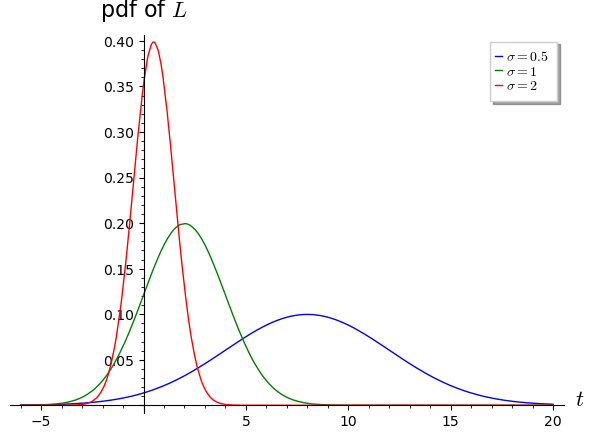

In [61]:
(sum(plot(lambda t, m=2 / s**2: np.exp(-(t - m)**2 / (4 * m)) / np.sqrt(4 * np.pi * m),
          (-6, 20), color=c, legend_label=f"$\\sigma = {s}$")
     for s, c in zip([0.5, 1, 2, 4], ["blue", "green", "red"]))
 ).show(axes_labels=[r"$t$", r"pdf of $L$"], figsize=6)

對稱性變成 L-density 的一個等式：
$$\Pr(L = -t) = e^{-t}\Pr(L = t).$$
理由：$L(-y) = -L(y)$，所以  
$\Pr(L = -t \mid x = 0) = \Pr(L = t \mid x = 1)$；  
而 $L(y) = t$ 表示 $\Pr(y \mid x = 1) = e^{-t}\Pr(y \mid x = 0)$。  
AWGN 把機率換成 density，等式相同：每個 $\mathcal N(m, 2m)$ 都滿足它。

### 每個 BMS channel 都是 BSCs 的混合

給定 $|L| = t > 0$，由對稱性，$L = -t$ 的條件機率是
$$\frac{e^{-t}}{1 + e^{-t}} = \frac1{1 + e^t}.$$
所以 BMS channel 可以這樣看：  
先隨機選一個 $p \in [0, 1/2]$，再讓 $x$ 經過 $\operatorname{BSC}(p)$，  
而接收端知道這次的 $p = 1 / (1 + e^t)$，因為它由 $|L|$ 決定。

BEC、BSC、AWGN 各自選到哪些 $p$、機率各是多少，  
留作週五作業。  
之後證明不等式時，常常先對 BSC 證明，再對 $p$ 取平均。

### Bhattacharyya parameter 與 total variation

以 $\Pr(y \mid 0)$ 簡寫 $\Pr(y \mid x = 0)$，定義
$$\begin{aligned}
B &= \sum_y\sqrt{\Pr(y \mid 0) \Pr(y \mid 1)}, \\
T &= \frac12\sum_y\bigl|\Pr(y \mid 0) - \Pr(y \mid 1)\bigr|.
\end{aligned}$$

$B$ 稱為 **Bhattacharyya parameter**，  
$T$ 是兩個輸出分布的 **total variation distance**。  
兩者都在 $[0, 1]$ 中，$B$ 越小越好，$T$ 越大越好。

$\operatorname{BSC}(p)$ 有 $B = 2\sqrt{p(1 - p)}$、$T = 1 - 2p$。  
混合後的輸出包含 $p$，所以兩者都是各個 BSC 的值的平均：
$$B = \mathbb E\bigl[2\sqrt{p(1 - p)}\bigr],\qquad T = \mathbb E[1 - 2p].$$

令 $P_e$ 是看到 $y$ 之後猜 $x$ 的最小錯誤機率，  
也就是依 $L$ 的正負號判斷（$L = 0$ 時隨便猜）的錯誤機率；  
對 L-density 也這樣定義，記為 $P_e(\mathsf a)$。  
給定 $p$ 時，這樣判斷錯的機率正是 $p$，  
所以 $P_e = \mathbb E[p]$，$T = 1 - 2P_e$。

用 $L$ 表示：$p = 1/(1 + e^{|L|})$，代入得
$$B = \mathbb E\bigl[\operatorname{sech}(L/2)\bigr],\qquad
T = \mathbb E\bigl[|\tanh(L/2)|\bigr].$$
兩者只用到 $|L|$，模擬時拿來估計很穩定。  
另外，由 $\Pr(y \mid 1) = e^{-L(y)}\Pr(y \mid 0)$，  
也可以寫成 $B = \mathbb E[e^{-L/2}]$。

| channel | $B$ | $T$ |
|---|---|---|
| $\operatorname{BEC}(\epsilon)$ | $\epsilon$ | $1 - \epsilon$ |
| $\operatorname{BSC}(p)$ | $2\sqrt{p(1 - p)}$ | $1 - 2p$ |
| AWGN | $e^{-1/(2\sigma^2)}$ | $1 - 2Q(1/\sigma)$ |

其中 $Q(z) = \Pr(Z > z)$，$Z \sim \mathcal N(0, 1)$。  
AWGN 的 $B$ 是 $L \sim \mathcal N(m, 2m)$ 的 $\mathbb E[e^{-L/2}] = e^{-m/4}$，  
其中 $m = 2/\sigma^2$。

$B$ 和 $P_e$ 互相控制：
$$\frac{1 - \sqrt{1 - B^2}}2 \le P_e \le \frac B2.$$
所以 $B \to 0$ 當且僅當 $P_e \to 0$。

右邊來自每個 BSC 的 $p \le \sqrt{p(1 - p)}$。  
左邊在 BSC 是等式，因為 $1 - B^2 = (1 - 2p)^2$；  
左邊是 $B$ 的凸函數，對 $p$ 取平均時用 Jensen 不等式。

### 兩種 Fourier transforms

VN 送出的 LLR 是收到的 LLRs 的和。  
這些 LLRs 獨立，  
所以輸出的 L-density 是輸入的 L-densities 的 convolution，  
記為 $\mathsf a \odot \mathsf b$。

Fourier（Laplace）transform $\mathbb E[e^{-sL}]$ 把 convolution 變成乘法；  
取 $s = 1/2$ 就是
$$B(\mathsf a \odot \mathsf b) = B(\mathsf a) B(\mathsf b).$$

為什麼是 $s = 1/2$？  
把 $t$ 換成 $-t$ 再用對稱性：
$$\begin{aligned}
\sum_t\Pr(L = t) e^{-st} &= \sum_t\Pr(L = -t) e^{st} \\
&= \sum_t\Pr(L = t) e^{-(1-s)t}.
\end{aligned}$$

所以 $\mathbb E[e^{-sL}]$ 對 $s = 1/2$ 對稱。  
這個凸函數在 $s = 0$ 與 $s = 1$ 都是 $1$，最小值 $B$ 在 $s = 1/2$。

CN 送出的 $\tanh(L/2)$ 是收到的 $\tanh(L_i/2)$ 的乘積。  
取絕對值再取對數，乘法就變成加法，  
所以這一側的 transform 是  
$\mathbb E\bigl[|\tanh(L/2)|^s\bigr]$（Mellin transform）。  
記 CN 的合併為 $\mathsf a \boxdot \mathsf b$，取 $s = 1$ 就是
$$T(\mathsf a \boxdot \mathsf b) = T(\mathsf a) T(\mathsf b).$$

BEC 的 $B = \epsilon$、$T = 1 - \epsilon$，  
這兩個乘法公式就是 1116 講義的  
VN 的 $\epsilon_1\epsilon_2$ 與 CN 的 $1 - (1 - \epsilon_1)(1 - \epsilon_2)$。  
BEC 的 L-density 由 $\epsilon$ 決定，  
所以 density evolution 只要追蹤一個數。

一般的 BMS channel 沒有這麼幸運：  
$B$ 只在 VN 相乘，$T$ 只在 CN 相乘。

下面用 AWGN 的 LLR 樣本驗證。  
`B` 與 `T` 用上面只含 $|L|$ 的公式估計。  
第一行驗證表中 AWGN 的 $B$，第二、三行驗證兩個乘法公式；  
最後兩行把 $B$ 與 $T$ 用在錯的 node，就不再相乘。

In [37]:
def B(L):
    return np.mean(1 / np.cosh(L / 2))

def T(L):
    return np.mean(np.abs(np.tanh(L / 2)))

In [38]:
def awgn_llr(sigma, N=10**6):
    return 2 / sigma**2 + 2 / sigma * rng.standard_normal(N)

In [39]:
La, Lb = awgn_llr(0.8), awgn_llr(1.2)
Lv = La + Lb
Lc = 2 * np.arctanh(np.tanh(La / 2) * np.tanh(Lb / 2))
print(B(La), np.exp(-1 / (2 * 0.8**2)))
print(B(Lv), B(La) * B(Lb))
print(T(Lc), T(La) * T(Lb))
print(B(Lc), B(La) * B(Lb))
print(T(Lv), T(La) * T(Lb))

0.45839106955238623 0.4578333617716143
0.3235964148451855 0.32382904725104156
0.46945050988150133 0.4694231441804201
0.8093260279443887 0.32382904725104156
0.8669884969965013 0.4694231441804201


## Density Evolution on BMS Channels

### Population dynamics

令 $\mathsf a_\ell$ 是第 $\ell$ 輪 VN 送出的訊息的 L-density，  
$\mathsf a_0 = \mathsf a_{\text{ch}}$ 是 channel 的 L-density。  
在樹的假設下，
$$\mathsf a_{\ell+1} = \mathsf a_{\text{ch}} \odot
\bigl(\mathsf a_\ell^{\boxdot(d_c-1)}\bigr)^{\odot(d_v-1)}.$$
Richardson–Urbanke 把 densities 量化後精確地計算這個遞迴。

這裡用比較簡單的 Monte Carlo：用 $N$ 個樣本代表 $\mathsf a_\ell$。  
CN 的輸出：從樣本中隨機抽 $d_c - 1$ 個，用 tanh rule 合併。  
VN 的輸出：再抽 $d_v - 1$ 個 CN 的輸出，加上 channel 的 LLR。  
這叫做 **population dynamics**。  
`de_bsc` 傳回每一輪的 $B(\mathsf a_\ell)$。

In [40]:
def de_bsc(p, dv=3, dc=6, N=10**5, iters=60):
    Lch = np.where(rng.random(N) < p, -1.0, 1.0) * np.log((1 - p) / p)
    v, Bs = Lch, [B(Lch)]
    for _ in range(iters):
        t = np.tanh(v[rng.integers(N, size=(N, dc - 1))] / 2).prod(axis=1)
        c = 2 * np.arctanh(np.clip(t, -1 + 1e-15, 1 - 1e-15))
        v = Lch + c[rng.integers(N, size=(N, dv - 1))].sum(axis=1)
        Bs.append(B(v))
    return Bs

1116 講義說 $(3, 6)$ codes 在 $\operatorname{BSC}(p)$ 上的 BP threshold 約為 $0.084$。  
下面對 $p = 0.010, 0.015, \ldots, 0.150$ 各跑一次，  
把幾個 $\ell$ 的 $B(\mathsf a_\ell)$ 畫成 $p$ 的函數。

In [41]:
grid = [k / 200 for k in range(2, 31)]
runs = {p: de_bsc(p) for p in grid}

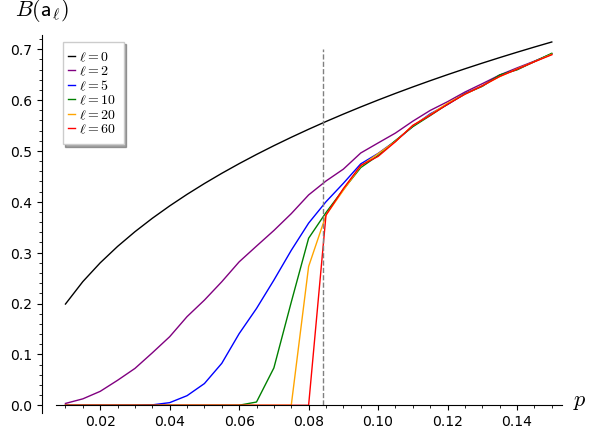

In [42]:
(sum(line([(p, runs[p][l]) for p in grid], color=c, legend_label=f"$\\ell = {l}$")
     for l, c in zip([0, 2, 5, 10, 20, 60], ["black", "purple", "blue", "green", "orange", "red"]))
 + line([(0.084, 0), (0.084, 0.7)], color="gray", linestyle="--")
 ).show(axes_labels=[r"$p$", r"$B(\mathsf{a}_\ell)$"], legend_loc="upper left", figsize=6)

$\ell = 0$ 是 channel 本身的 $B = 2\sqrt{p(1 - p)}$。  
$\ell$ 越大，曲線越接近一個階梯：  
灰色虛線 $0.084$ 的左邊 $B \to 0$，右邊停在正的值。  
樣本數有限，所以數值會有一點起伏。

### CN 的 Bhattacharyya parameter

追蹤整個 density 很貴，而且只給出數值。  
能不能只追蹤 $B$？  
VN 沒問題，$B$ 相乘；  
CN 輸出的 $B$ 卻不只由輸入的 $B$ 決定，  
但可以夾在 BEC 與 BSC 之間。

**定理：** 對 BMS channels 的 L-densities $\mathsf a$ 與 $\mathsf b$，
$$\begin{aligned}
B(\mathsf a \boxdot \mathsf b)
&\le 1 - \bigl(1 - B(\mathsf a)\bigr)\bigl(1 - B(\mathsf b)\bigr), \\
B(\mathsf a \boxdot \mathsf b)
&\ge \sqrt{1 - \bigl(1 - B(\mathsf a)^2\bigr)\bigl(1 - B(\mathsf b)^2\bigr)}.
\end{aligned}$$
兩者都是 BEC 時上界是等號，都是 BSC 時下界是等號。

先看 $\operatorname{BSC}(p)$ 與 $\operatorname{BSC}(q)$，  
CN 的輸出是串聯的 $\operatorname{BSC}(p \star q)$。  
令 $s = 2\sqrt{p(1 - p)}$、$t = 2\sqrt{q(1 - q)}$。  
由 $1 - s^2 = (1 - 2p)^2$，
$$\begin{aligned}
B(\mathsf a \boxdot \mathsf b) &= \sqrt{1 - (1 - 2p)^2(1 - 2q)^2} \\
&= \sqrt{1 - (1 - s^2)(1 - t^2)}.
\end{aligned}$$
這就是下界的等號。

上界：$\sqrt{s^2 + t^2 - s^2t^2} \le s + t - st$，  
因為兩邊平方後相減，差是 $2st(1 - s)(1 - t) \ge 0$。  
等號在 $s, t \in \{0, 1\}$ 時成立，也就是 BEC 用到的兩種 BSCs。

一般的情形，$\mathsf a$ 與 $\mathsf b$ 各是 BSCs 的混合，選到的 $p$ 與 $q$ 獨立，  
CN 的輸出是 $\operatorname{BSC}(p \star q)$ 的混合，所以
$$B(\mathsf a \boxdot \mathsf b)
= \mathbb E\Bigl[\sqrt{s^2 + t^2 - s^2t^2}\Bigr].$$

上界：逐項用上面的不等式，再用 $\mathbb E[st] = \mathbb E[s]\mathbb E[t]$。  
下界：$\sqrt{t^2 + (1 - t^2)s^2}$ 對 $s$ 是凸函數，對 $t$ 也是，  
依序對 $s$ 與 $t$ 用 Jensen 不等式。

### VN 的 total variation

同樣地，CN 的 $T$ 相乘，VN 的 $T$ 有下界：
$$1 - T(\mathsf a \odot \mathsf b)
\ge \bigl(1 - T(\mathsf a)\bigr)\bigl(1 - T(\mathsf b)\bigr),$$
兩者都是 BEC 時是等號。

$1 - T = 2P_e$。  
$\operatorname{BSC}(p)$ 與 $\operatorname{BSC}(q)$ 的兩份觀測一起判斷：  
兩者一致時照判，不一致時相信 $p$ 比較小的那一個，  
錯誤機率是 $\min(p, q)$。  
$p, q \le 1/2$，所以 $2\min(p, q) \ge 2p \cdot 2q$，再對 $p$ 與 $q$ 取平均。

### 把 density evolution 夾住

令 $x_\ell = B(\mathsf a_\ell)$、$B_{\text{ch}} = B(\mathsf a_{\text{ch}})$。  
VN 的 $B$ 相乘，CN 重複使用上界：
$$x_{\ell+1} \le B_{\text{ch}}\bigl(1 - (1 - x_\ell)^{d_c-1}\bigr)^{d_v-1}.$$
把右邊記為 $\overline f(x_\ell)$。  
它正是 1116 講義的 BEC density evolution，只是 $\epsilon$ 換成 $B_{\text{ch}}$。

注意 $x_{\ell+1}$ 不是 $x_\ell$ 的函數：它由整個 $\mathsf a_\ell$ 決定，  
$B$ 相同的兩個 L-densities，下一輪的 $B$ 可以不同。  
需要遞增的是 $\overline f$，而 $1 - (1 - x)^{d_c-1}$ 在 $[0, 1]$ 上遞增而且非負。  
令 $e_\ell$ 是 $\operatorname{BEC}(B_{\text{ch}})$ 的 density evolution，  
$e_0 = x_0 = B_{\text{ch}}$。  
若 $x_\ell \le e_\ell$，則
$x_{\ell+1} \le \overline f(x_\ell) \le \overline f(e_\ell) = e_{\ell+1}$。

所以每一輪都有 $x_\ell \le e_\ell$。  
**結論：** 若 $B_{\text{ch}} < 0.4294$，則 $(3, 6)$ codes 的 BP 成功。  
$\operatorname{BSC}(p)$ 的條件是 $p < 0.0484$，AWGN 的條件是 $\sigma < 0.769$。

反方向，CN 重複使用下界：
$$x_{\ell+1}
\ge B_{\text{ch}}\bigl(1 - (1 - x_\ell^2)^{d_c-1}\bigr)^{(d_v-1)/2}.$$
把右邊記為 $\underline f(x_\ell)$。

若某個 $0 < \bar x \le B_{\text{ch}}$ 滿足 $\underline f(\bar x) \ge \bar x$，  
則由 $x_0 = B_{\text{ch}} \ge \bar x$ 與 $\underline f$ 遞增歸納，每一輪都有
$$x_{\ell+1} \ge \underline f(x_\ell) \ge \underline f(\bar x) \ge \bar x,$$
BP 失敗。

同樣地，令 $z_\ell = 1 - T(\mathsf a_\ell)$，CN 的 $T$ 相乘，VN 用下界：
$$z_{\ell+1} \ge z_{\text{ch}}\bigl(1 - (1 - z_\ell)^{d_c-1}\bigr)^{d_v-1},
\qquad z_{\text{ch}} = 2P_e.$$
又是 BEC 的遞迴，這次是下界：$2P_e > 0.4294$ 時 BP 失敗。

所以在 density evolution 中，BMS channel 夾在兩個 BEC 之間：  
$\operatorname{BEC}(B)$ 成功時它也成功，$\operatorname{BEC}(2P_e)$ 失敗時它也失敗。  
$P_e \le B/2$，所以 $\operatorname{BEC}(2P_e)$ 確實比 $\operatorname{BEC}(B)$ 好。

下面用 $\operatorname{BSC}(p)$ 畫出藍色的 $\overline f$ 與紅色的 $\underline f$，  
並把 population dynamics 的 $(x_\ell, x_{\ell+1})$ 畫成綠點。  
綠點一定落在兩條曲線之間。

In [43]:
x = var("x")

def staircase(p, dv=3, dc=6):
    b = 2 * sqrt(p * (1 - p))
    upper = b * (1 - (1 - x)**(dc - 1))**(dv - 1)
    lower = b * (1 - (1 - x**2)**(dc - 1))**((dv - 1) / 2)
    pts = list(zip(runs[p][:-1], runs[p][1:]))
    return (plot(upper, (x, 0, 0.7)) + plot(lower, (x, 0, 0.7), color="red")
            + plot(x, (x, 0, 0.7), color="black", linestyle="--")
            + point(pts, color="green", size=15) + text(f"$p = {float(p)}$", (0.15, 0.6)))

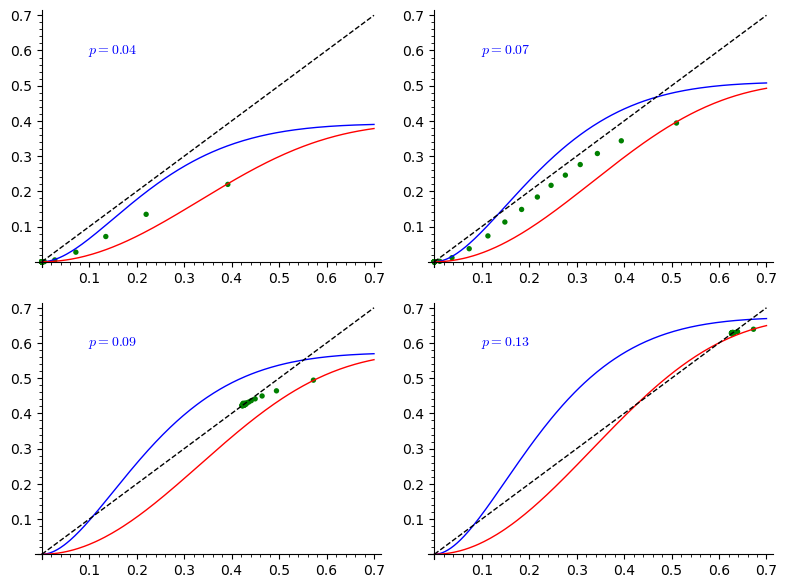

In [44]:
graphics_array([staircase(p) for p in [0.04, 0.07, 0.09, 0.13]], 2, 2).show(figsize=8)

$p = 0.04$ 時藍線已經在對角線下方，保證成功；  
$p = 0.13$ 時紅線碰到對角線，保證失敗。  
$p = 0.07$ 與 $0.09$ 時兩條線都不能判斷，  
真正的 threshold $0.084$ 就在其中。  
每張圖的第一個點都在紅線上：  
第一輪 CN 收到的都是 BSC，下界是等號。

下面用數值找出兩個界保證的範圍。  
上界需要 $2\sqrt{p(1 - p)} < 0.4294$。  
下界要找最小的 $B_{\text{ch}}$，使某個 $\bar x \le B_{\text{ch}}$
滿足 $\underline f(\bar x) \ge \bar x$，  
`lower_fails` 在格點上檢查這件事，再用二分法找出這個 $B_{\text{ch}}$。

In [45]:
xs = np.linspace(1e-6, 1, 10**5)

def lower_fails(b, dv=3, dc=6):
    xb = xs[xs <= b]
    return np.any(b * (1 - (1 - xb**2)**(dc - 1))**(0.5 * (dv - 1)) >= xb)

In [46]:
lo, hi = 0.0, 1.0
for _ in range(40):
    mid = (lo + hi) / 2
    lo, hi = (lo, mid) if lower_fails(mid) else (mid, hi)
p_of_b = lambda b: (1 - sqrt(1 - b**2)) / 2
print(p_of_b(0.4294), hi, p_of_b(hi))

0.04844279432169396 0.6553165757613897 0.12232282782369319


$B = 2\sqrt{p(1 - p)}$ 反解得 $p = (1 - \sqrt{1 - B^2})/2$。  
所以 $\operatorname{BSC}(p)$ 上，$p < 0.0484$ 保證成功，$p > 0.1224$ 保證失敗。  
後者比 capacity 的 $0.110$ 還大，所以不是新的資訊，  
但它和上界用的是同一套推理。

### 同 capacity 時 BSC 的 $B$ 最大

BMS channel 的 capacity 是
$$C = 1 - \mathbb E\bigl[h(p)\bigr],$$
這裡不證明：接收端知道 $p$，平均每個 bit 帶有 $1 - h(p)$ 的資訊。  
BEC 是 $1 - \epsilon$，BSC 是 $1 - h(p)$，和 1116 講義一致。

**定理：** capacity 為 $C$ 的 BMS channels 中，  
BEC 的 $B$ 最小，BSC 的 $B$ 最大：
$$1 - C \le B \le 2\sqrt{p_C(1 - p_C)},$$
其中 $p_C \le 1/2$ 滿足 $h(p_C) = 1 - C$。

沿著 BSC 這一族，  
把 $b = 2\sqrt{p(1 - p)}$ 看成 $c = 1 - h(p)$ 的函數 $\varphi(c)$。  
下圖顯示 $\varphi$ 是凹函數，而且 $\varphi(0) = 1$、$\varphi(1) = 0$。  
一般的 BMS channel 有 $B = \mathbb E[\varphi(c)]$ 與 $C = \mathbb E[c]$。  
由 Jensen 不等式，$B \le \varphi(C)$；  
凹函數在弦 $1 - c$ 的上方，所以 $B \ge \mathbb E[1 - c] = 1 - C$。

圖中 AWGN 的點用 $C = 1 - \mathbb E\bigl[\log_2(1 + e^{-L})\bigr]$ 計算：  
對每個 BSC，$\log_2(1 + e^{-L})$ 對 $L$ 的正負號取平均，恰好是 $h(p)$。

In [47]:
def awgn_capacity(sigma):
    return 1 - np.mean(np.logaddexp(0, -awgn_llr(sigma))) / np.log(2)

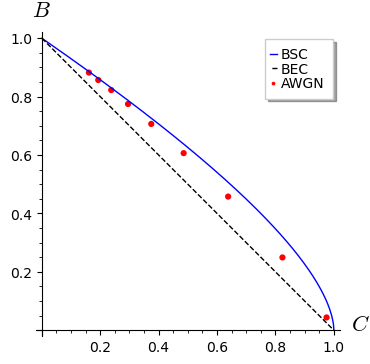

In [48]:
p = var("p")
h = -p * log(p, 2) - (1 - p) * log(1 - p, 2)
awgn = [(awgn_capacity(s), np.exp(-1 / (2 * s**2))) for s in np.arange(0.4, 2.01, 0.2)]
(parametric_plot((1 - h, 2 * sqrt(p * (1 - p))), (p, 1e-6, 0.5), legend_label="BSC")
 + line([(0, 1), (1, 0)], color="black", linestyle="--", legend_label="BEC")
 + point(awgn, color="red", size=20, legend_label="AWGN")
 ).show(axes_labels=[r"$C$", r"$B$"], figsize=5)

**推論：** capacity 至少是 $1 - h(0.0484) \approx 0.72$ 的 BMS channel，  
$B \le 2\sqrt{0.0484 \cdot 0.9516} < 0.4294$，  
所以 $(3, 6)$ codes 的 BP 一定成功，  
不需要知道 channel 長什麼樣子。

Rate $1/2$ 的 codes 要 capacity $0.72$ 才保證成功，這個界很寬鬆，  
但它對所有 BMS channels 同時成立。

## Irregular LDPC Codes

### Degree distributions

回到 BEC。  
1116 講義的延伸話題用 edge perspective 描述 degrees：  
$\lambda_i$ 是連到 degree $i$ 的 VN 的邊所佔的比例，$\rho_i$ 對 CNs 同樣定義，
$$\lambda(x) = \sum_i\lambda_i x^{i-1},\qquad \rho(x) = \sum_i\rho_i x^{i-1}.$$
$(d_v, d_c)$-regular 就是 $\lambda(x) = x^{d_v-1}$、$\rho(x) = x^{d_c-1}$。

令 $E$ 是邊數。  
Degree $i$ 的 VNs 有 $E\lambda_i/i$ 個，  
所以 VNs 共有 $E\sum_i\lambda_i/i = E\int_0^1\lambda(x)\,dx$ 個，CNs 也一樣。  
因此 design rate 是
$$R = 1 - \frac{\int_0^1\rho(x)\,dx}{\int_0^1\lambda(x)\,dx}.$$

### Density evolution 與 threshold

一條邊連到 degree $i$ 的 VN 的機率是 $\lambda_i$，  
這時其他 $i - 1$ 條邊都送來「$\mathrm e$」的機率是 $y^{i-1}$，  
平均起來是 $\lambda(y)$。  
CN 也一樣，所以 1116 講義的遞迴與 threshold 變成
$$\begin{aligned}
x_{\ell+1} &= \epsilon\lambda\bigl(1 - \rho(1 - x_\ell)\bigr), \\
\epsilon^* &= \inf_{0<x\le1}\frac{x}{\lambda(1 - \rho(1 - x))}.
\end{aligned}$$

1116 講義也說明了 BEC 上 rate $R$ 的 code 必須 $\epsilon \le 1 - R$。  
目標是找 $\lambda$ 與 $\rho$，使 $\epsilon^*$ 接近 $1 - R$。

### Stability condition

$x$ 很小時，$1 - \rho(1 - x) \approx \rho'(1) x$，$\lambda(y) \approx \lambda_2 y$，所以
$$\epsilon\lambda\bigl(1 - \rho(1 - x)\bigr)
\approx \epsilon\lambda_2\rho'(1) x.$$
$x_\ell \to 0$ 需要 $\epsilon\lambda_2\rho'(1) \le 1$，  
也就是 $\epsilon^* \le \frac1{\lambda_2\rho'(1)}$，稱為 **stability condition**。

$\lambda_2 = 0$ 時沒有限制，例如 $(3, 6)$：$x$ 很小時下一輪是 $O(x^2)$。  
但逼近 capacity 的 degree distributions 有很多 degree $2$ 的 VNs，  
stability condition 限制了它們的數量。

### Right-regular 序列

Shokrollahi 的構造：所有 CNs 的 degree 都是 $r$，$\rho(x) = x^{r-1}$。  
令 $\alpha = 1/(r - 1)$，展開
$$1 - (1 - x)^\alpha = \sum_{i\ge1} a_i x^i.$$

展開的係數都是正的：
$$a_i = \frac{\alpha(1 - \alpha)(2 - \alpha)\cdots(i - 1 - \alpha)}{i!} > 0.$$

取前 $N - 1$ 項並正規化：
$$\lambda(x) = \frac1c\sum_{i=1}^{N-1} a_i x^i,\qquad
c = \sum_{i=1}^{N-1} a_i < 1.$$
VN 的 degrees 是 $2, 3, \ldots, N$，其中 $\lambda_2 = a_1/c = \alpha/c$。

令 $y = 1 - (1 - x)^{r-1}$，則 $(1 - y)^\alpha = 1 - x$。  
截掉的項都是正的，所以
$$\epsilon\lambda(y) \le \frac\epsilon c\bigl(1 - (1 - y)^\alpha\bigr)
= \frac\epsilon c x.$$
$\epsilon < c$ 時右邊小於 $x$，所以 $\epsilon^* \ge c$。

另一方面，$\lambda_2\rho'(1) = \frac\alpha c(r - 1) = \frac1c$，  
stability condition 給出 $\epsilon^* \le c$。  
所以 threshold 恰好是 $\epsilon^* = c$，  
而且 stability condition 是唯一的瓶頸。

`right_regular` 用 $a_{i+1} = a_i(i - \alpha)/(i + 1)$ 計算係數，  
傳回 $\lambda_2, \ldots, \lambda_N$ 與 $c$；`rate` 依上面的公式計算 design rate。

In [49]:
def right_regular(r, N):
    alpha = 1.0 / (r - 1)
    i = np.arange(1, N - 1)
    a = alpha * np.cumprod(np.r_[1, (i - alpha) / (i + 1)])
    return a / a.sum(), a.sum()

def rate(lam, r):
    return 1 - (1.0 / r) / np.sum(lam / np.arange(2, len(lam) + 2))

對每個 $r$，取 rate 不低於 $1/2$ 的最大 $N$。  
每一行依序是 $r$、$N$、rate $R$、threshold $c$、差距 $1 - R - c$，  
最後一項是 threshold 離 capacity 還有多遠。

In [50]:
for r in range(4, 11):
    N = 2
    while rate(right_regular(r, N + 1)[0], r) >= 0.5:
        N += 1
    lam, c = right_regular(r, N)
    print(r, N, np.round(rate(lam, r), 4), np.round(c, 4), np.round(1 - rate(lam, r) - c, 4))

4 2 0.5 0.3333 0.1667
5 5 0.5085 0.436 0.0554
6 12 0.5062 0.4721 0.0217
7 28 0.5011 0.4898 0.0091
8 60 0.5004 0.4954 0.0042
9 125 0.5002 0.4978 0.002
10 256 0.5002 0.4988 0.001


$r = 4$ 時 $\lambda(x) = x$，  
就是 1116 講義的 $(2, 4)$-regular，threshold $1/3$。  
$r$ 變大時差距很快趨近 $0$，但最大的 VN degree $N$ 急速變大：  
$r = 10$ 時差距約 $0.001$，$N$ 卻是 $256$。

### 逼近 capacity 的代價

上面的不等式在 $x$ 很小時幾乎是等式，  
所以 $\epsilon$ 接近 $c$ 時，每一輪 erasures 只剩下約 $\epsilon/c$ 倍，  
階梯在曲線與對角線之間很窄的通道中前進。  
下圖畫出每一輪剩下的比例 $f(x)/x$，  
比較 $(3, 6)$ 與 $r = 8$、$N = 60$ 的 right-regular，  
$\epsilon$ 都取 threshold 的 $95\%$。

In [51]:
lam8, c8 = right_regular(8, 60)
f36 = lambda eps, x: eps * (1 - (1 - x)**5)**2
f8 = lambda eps, x: eps * np.polyval(np.r_[lam8[::-1], 0], 1 - (1 - x)**7)

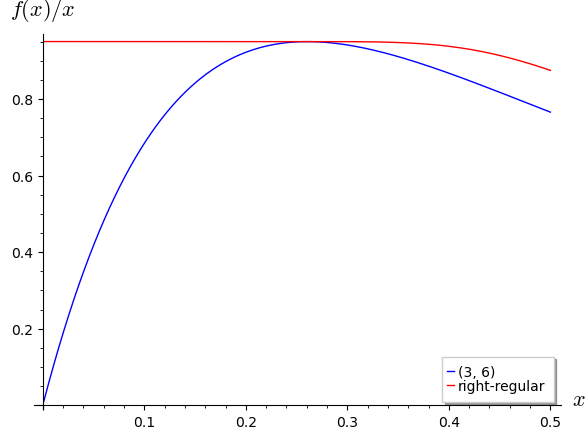

In [52]:
grid = np.linspace(0.001, 0.5, 500)
(line(list(zip(grid, f36(0.95 * 0.4294, grid) / grid)), legend_label="(3, 6)")
 + line(list(zip(grid, f8(0.95 * c8, grid) / grid)), color="red", legend_label="right-regular")
 ).show(axes_labels=[r"$x$", r"$f(x)/x$"], figsize=6)

$(3, 6)$ 的比例只在 $x \approx 0.25$ 附近接近 $0.95$，其他地方小得多；  
right-regular 的比例在 $x < 0.3$ 的整個範圍都是 $0.95$。  
下面數出 erasure 機率降到 $10^{-6}$ 以下需要幾輪。

In [53]:
def iterations(f, eps, tol=1e-6):
    x, n = eps, 0
    while x > tol:
        x, n = f(eps, x), n + 1
    return n

print(iterations(f36, 0.95 * 0.4294), iterations(f8, 0.95 * c8))

21 253


這是一般的現象，Shokrollahi 稱為 **flatness condition**：  
threshold 逼近 capacity 時，  
$\epsilon\lambda(1 - \rho(1 - x))$ 必須在整個區間上貼著 $x$。  
所以逼近 capacity 的代價除了很大的 degrees，還有很多輪的 BP。

## Spatial Coupling

### 把 codes 串成一條鏈

1116 講義的延伸話題提過 spatially coupled LDPC codes。  
把 $M$ 個 $(d_v, d_c)$-regular codes 排在位置 $1, 2, \ldots, M$，  
每個位置的 VNs 一樣多。  
位置 $i$ 的 VN 的每一條邊，  
隨機連到位置 $i, i + 1, \ldots, i + w - 1$ 之一的 CN，  
所以 CN 的位置從 $1$ 到 $M + w - 1$。

兩端的 CNs 只有一部分的邊連得到 VNs，degree 比較小，  
就像旁邊有已知的 bits。  
CNs 比 VNs 多出 $w - 1$ 個位置，所以 design rate 至少是
$$1 - \frac{d_v}{d_c}\cdot\frac{M + w - 1}{M},$$
$M \to \infty$ 時趨近 $1 - d_v/d_c$。

Felström–Zigangirov（1999）最早提出這種結構，  
稱為 LDPC convolutional codes。  
threshold saturation 由 Kudekar–Richardson–Urbanke（2011）證明。

### Coupled density evolution

令 $x_i$ 是位置 $i$ 的 VN 送出「$\mathrm e$」的機率，  
位置 $1$ 到 $M$ 以外的 $x_i = 0$。  
CN 收到的每個訊息平均來自 $w$ 個位置，VN 也一樣：
$$\begin{aligned}
y_j &= 1 - \Bigl(1 - \frac1w\sum_{k=0}^{w-1} x_{j-k}\Bigr)^{d_c-1}, \\
x_i &\leftarrow \epsilon\Bigl(\frac1w\sum_{k=0}^{w-1} y_{i+k}\Bigr)^{d_v-1}.
\end{aligned}$$

`coupled_de` 用 `np.convolve` 計算兩個平均，  
並記下每一輪的 $x_1, \ldots, x_M$。  
下面取 $(3, 6)$、$M = 50$、$w = 3$、$\epsilon = 0.47$，  
超過 1116 講義的 threshold $0.4294$。

In [54]:
def coupled_de(eps, M=50, w=3, dv=3, dc=6, iters=300):
    x, k = np.full(M, eps), np.ones(w) / w
    history = [x]
    for _ in range(iters):
        y = 1 - (1 - np.convolve(x, k))**(dc - 1)
        x = eps * np.convolve(y, k, mode="valid")**(dv - 1)
        history.append(x)
    return history

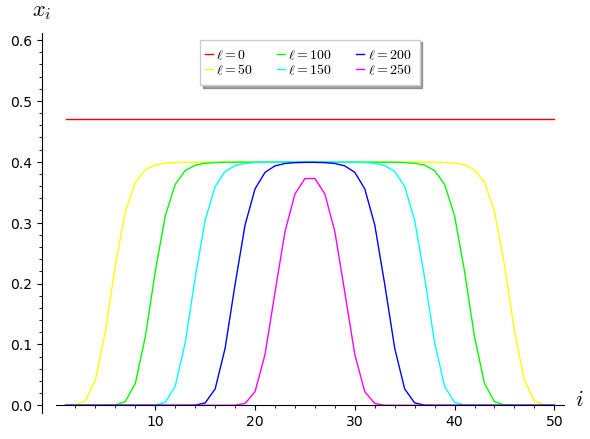

In [55]:
history = coupled_de(0.47)
sum(line(list(enumerate(history[t], 1)), color=hue(t / 300), legend_label=f"$\\ell = {t}$")
    for t in [0, 50, 100, 150, 200, 250]
    ).show(axes_labels=[r"$i$", r"$x_i$"], ymax=0.6, legend_loc="upper center", legend_ncol=3, figsize=6)

一開始所有位置都是 $0.47$。  
兩端的 CNs 比較輕，最先補回 erasures；  
接著「已知」的波從兩端往中間推進，速度大致固定。  
波還沒到的地方停在 uncoupled 的不動點，約 $0.4$。  
兩道波在中間會合之後，所有 erasures 都補回來了。

下面比較 uncoupled 的不動點與 coupled chain 最後的最大值，  
再試 $\epsilon = 0.48$ 與 $0.49$。

In [56]:
x1 = 0.47
for _ in range(1000):
    x1 = 0.47 * (1 - (1 - x1)**5)**2
print(x1, history[-1].max())
for eps in [0.48, 0.49]:
    print(eps, coupled_de(eps, iters=3000)[-1].max())

0.39942258671419556 0.0
0.48 0.0
0.49 0.43537693848364667


$\epsilon = 0.48$ 也成功，$0.49$ 則失敗，  
所以這條鏈的 threshold 在 $0.48$ 與 $0.49$ 之間，  
遠高於 uncoupled 的 $0.4294$。

### Potential 與 threshold saturation

為什麼波會前進？  
令 $f(u) = \epsilon u^{d_v-1}$、$g(x) = 1 - (1 - x)^{d_c-1}$，  
uncoupled 的遞迴是 $x \leftarrow f(g(x))$。

定義 **potential**
$$U(x) = x g(x) - \int_0^x g(z)\,dz - \frac\epsilon{d_v} g(x)^{d_v}.$$
微分得 $U'(x) = g'(x)\bigl(x - f(g(x))\bigr)$。

所以 $U$ 的臨界點正是遞迴的不動點；  
$x > f(g(x))$ 時 $U$ 遞增，遞迴讓 $x$ 變小，  
也就是沿著 $U$ 往低處走。  
$U(0) = 0$。  
Uncoupled 的遞迴從 $x = \epsilon$ 出發，只能走到最近的谷底，  
即使 $x = 0$ 那個谷比較深也到不了。

In [57]:
def potential(x, eps, dv=3, dc=6):
    g = 1 - (1 - x)**(dc - 1)
    return x * g - (x - (1 - (1 - x)**dc) / dc) - eps * g**dv / dv

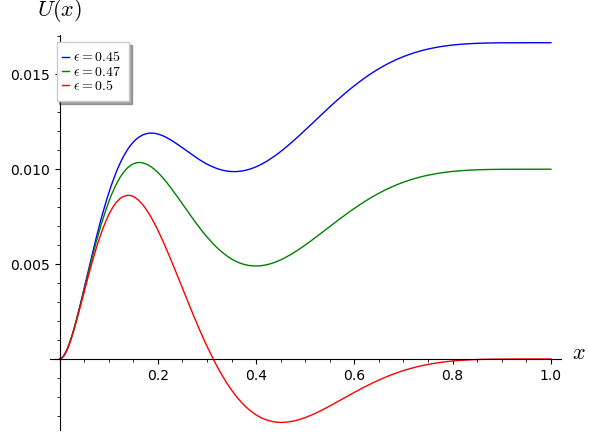

In [58]:
sum(plot(potential(x, eps), (x, 0, 1), color=c, legend_label=f"$\\epsilon = {float(eps)}$")
    for eps, c in [(0.45, "blue"), (0.47, "green"), (0.5, "red")]
    ).show(axes_labels=[r"$x$", r"$U(x)$"], figsize=6)

三條曲線在 $x = 0$ 附近都是正的。  
$\epsilon = 0.45$ 與 $0.47$ 時，另一個谷底仍在 $0$ 的上方；  
$\epsilon = 0.5$ 時它掉到 $0$ 以下，比 $x = 0$ 更深。

Coupled chain 的兩端固定在 $x = 0$。  
若 $x = 0$ 是最深的谷，也就是 $U(x) > 0$ 對所有 $0 < x \le 1$ 成立，  
兩端的低谷就會往中間擴張，像一道波。  
所以 $w$ 與 $M$ 夠大時，coupled chain 的 BP threshold 是
$$\epsilon^{\text{pot}} = \sup\{\epsilon :
U(x) > 0\text{ for all }0 < x \le 1\}.$$

這叫做 **threshold saturation**，  
用 potential 的證明來自 Yedla–Jian–Nguyen–Pfister（2012）。  
uncoupled code 用 optimal（MAP）decoder 時，  
threshold 也正是 $\epsilon^{\text{pot}}$，這裡不證明。

下面對 $(d_v, 2d_v)$ 比較 uncoupled 的 BP threshold 與 $\epsilon^{\text{pot}}$。

In [59]:
for dv in [3, 4, 5, 6]:
    eps_bp = (xs / (1 - (1 - xs)**(2 * dv - 1))**(dv - 1)).min()
    eps_pot = find_root(lambda e: potential(xs, e, dv, 2 * dv).min(), 0.3, 0.6)
    print((dv, 2 * dv), np.round(eps_bp, 4), np.round(eps_pot, 4))

(3, 6) 0.4294 0.4882
(4, 8) 0.3834 0.4977
(5, 10) 0.3416 0.4995
(6, 12) 0.3075 0.4999


Uncoupled 的 BP threshold 隨 $d_v$ 變大而變差，  
potential threshold 卻往 capacity $0.5$ 逼近。  
Coupling 之後兩全其美：degrees 是 regular 的，decoder 是 BP，  
threshold 卻接近 capacity。  
代價是 rate 損失 $O(w/M)$，  
而且波要走過整條鏈，輪數大約正比於 $M$。

## 週五作業

### BMS channels 的 mixing distribution

講義說明每個 BMS channel 都可以看成：  
先依某個分布隨機選 $p \in [0, 1/2]$，再讓 $x$ 經過 $\operatorname{BSC}(p)$，  
而接收端知道這次的 $p$。  
$p$ 的分布稱為這個 channel 的 **mixing distribution**。

1. 假設 $\mathsf a$ 是 pmf，也就是 $L$ 只取可數個值，可以包含 $+\infty$。  
   寫出 mixing distribution 的 pmf $g(p)$。  
   $L = 0$ 與 $L = +\infty$ 各對應哪一個 $p$？
2. 假設 $\mathsf a$ 是 pdf，  
   寫出 mixing distribution 在 $0 < p < 1/2$ 上的 pdf $g(p)$。

我們在這邊故意重複使用 $g$ 和 $\mathsf a$：  
文獻也常常用同一個符號表示 pmf 與 pdf 的歧義 placeholder。  
這樣不合法但合理，  
因為 distribution theory 裡的 distribution  
同時是 pmf 跟 pdf 的推廣，所以最後變成  
「你不懂就當作是 pdf，如果連 pdf 也不懂就當作是 pmf」。

3. 寫出 $\operatorname{BEC}(\epsilon)$ 與 $\operatorname{BSC}(p_0)$ 的 $g$。
4. BPSK 加上 AWGN，取 $A = 1$，寫出 $g$，  
   並畫出 $\sigma = 0.5$、$0.8$、$1.2$ 的 $g$。  
   用數值積分檢查 $\int g = 1$，  
   以及 $\int p\,g$ 與 $\int 2\sqrt{p(1 - p)}\,g$ 分別是講義的 $P_e$ 與 $B$。

$g$ 應該長得像下圖，但請自己用程式畫一張；  
縱軸截在 $15$：$\sigma = 0.5$ 與 $0.8$ 的峰值很高，  
而且比 $p = 0.0005$ 還靠近 $0$，所以圖中看不到。  
![σ = 0.5、0.8、1.2 時 AWGN 的 mixing distribution 的 pdf](1123/awgn-mixing-density.png)

### 週一作業

機率課學過的分布，會在意想不到的地方出現。  
例如 AWGN 的 L-density 是 $\mathcal N(m, 2m)$，其中 $m = 2/\sigma^2$。  
兩個 AWGN 做 VN 合併，得到的還是同一種 Gaussian：
$$\mathcal N(m, 2m) \odot \mathcal N(m', 2m')
= \mathcal N(m + m', 2m + 2m'),$$
而 $B = e^{-m/4}$ 把 $m$ 的加法變成乘法。  
下面的例子發生在 CN 的合併。

**定義：** Poisson channel $\operatorname{PC}(\lambda, q)$  
先抽 $N \sim \operatorname{Poisson}(\lambda)$，  
讓 $x$ 依序經過 $N$ 個 $\operatorname{BSC}(q)$，  
接收端收到輸出，而且知道 $N$。

5. 寫出 $\operatorname{PC}(\lambda, q)$ 的 $g$ 與 L-density 的 pmf。
6. 證明 $\operatorname{PC}(\lambda, q)$ 與 $\operatorname{PC}(\mu, q)$ 的 CN 合併  
   是 $\operatorname{PC}(\lambda + \mu, q)$，  
   並算出 $T\bigl(\operatorname{PC}(\lambda, q)\bigr)$。  
   這裡用到了 Poisson 分布的哪個性質？  
   它和 AWGN 的 $B = e^{-m/4}$ 有什麼對應？

7. $\operatorname{PC}(\lambda, 1/2)$ 是哪一個 channel？  
   固定 $2q\lambda = s$ 而讓 $\lambda \to \infty$，  
   $\operatorname{PC}(\lambda, q)$ 趨近哪一個 channel？

8. 令 $W$ 是 mixing distribution 為 $[0, 1/2]$ 上均勻分布的 BMS channel。  
   求 $|\tanh(L/2)|$ 的分布與 $T(W)$。  
   兩個 $W$ 做 CN 合併，$|\tanh(L/2)|$ 的 pdf 是什麼？$n$ 個呢？  
   提示：取 $-\ln$，這些分布你在機率課都見過。

額外練習不用交：

- 把定義中的 $\operatorname{BSC}(q)$ 換成任意的 BMS channel，  
  也就是讓 $N$ 個獨立的這種 channel 做 CN 合併，  
  $N = 0$ 時接收端直接看到 $x$。  
  第 6 題的結論還成立嗎？  
  把 CN 合併換成 VN 合併呢？

- 1116 講義的 min-sum 把兩個輸入的 tanh rule  
  $c(a, b) = 2\operatorname{artanh}\bigl(\tanh(a/2)\tanh(b/2)\bigr)$  
  近似成 $\operatorname{sign}(a)\operatorname{sign}(b)\min(|a|, |b|)$。  
  證明誤差有封閉形式：
  $$\begin{aligned}
  c(a, b) &= \operatorname{sign}(a)\operatorname{sign}(b)\min(|a|, |b|) \\
  &\quad + \ln\frac{1 + e^{-|a+b|}}{1 + e^{-|a-b|}}.
  \end{aligned}$$

再說明誤差總是讓絕對值變小，而且絕對值不超過 $\ln2$；  
$|a|$ 與 $|b|$ 相差很多時，誤差趨近 $0$。  
這也解釋了 1116 講義的 offset min-sum。  
提示：先證明 $c(a, b) = \ln\frac{1 + e^{a+b}}{e^a + e^b}$。